<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

-
-

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [5]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/pymes_colombia.csv')
df.head()

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [6]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   empresa             250 non-null    object 
 1   ventas_anuales      250 non-null    float64
 2   empleados           250 non-null    int64  
 3   productividad       250 non-null    float64
 4   margen_operacional  250 non-null    float64
 5   endeudamiento       250 non-null    float64
 6   exportaciones_pct   250 non-null    float64
 7   inversion_tic       250 non-null    float64
 8   antiguedad          250 non-null    int64  
 9   crecimiento_ventas  250 non-null    float64
 10  sector              250 non-null    object 
 11  region              250 non-null    object 
dtypes: float64(7), int64(2), object(3)
memory usage: 23.6+ KB


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,"6,242.05",63.07,92.82,7.83,52.17,13.44,2.88,17.16,4.94
std,"5,547.71",56.20,39.72,7.27,17.29,18.34,2.97,9.98,10.93
min,66.70,2.00,8.34,-5.90,22.30,0.00,0.00,1.00,-17.30
25%,426.80,8.00,67.22,3.23,40.55,0.60,0.90,9.00,-0.20
50%,"4,694.50",55.00,87.17,6.85,47.10,3.85,1.70,16.00,3.20
75%,"10,491.10",81.75,114.13,12.00,59.15,16.45,3.08,26.00,8.25
max,"22,240.30",214.00,285.75,24.70,94.20,64.00,10.90,42.00,35.60


In [7]:
n_nulos = int(df.isnull().sum().sum())
conteo_sector = df['sector'].value_counts()

In [8]:
### TU CÓDIGO AQUÍ ###

print("Valores faltantes en toda la base:", n_nulos)
print(conteo_sector)

Valores faltantes en toda la base: 0
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [10]:
analisis_descriptivo = """
### TU TEXTO AQUÍ ###
"""

analisis_descriptivo = """
1. la base no tiene valores faltantes, como no hay datos faltantes no es necesario imputar nada antes de agrupar.
2. Las escalas son muy distintas: la desviación estándar de ventas_anuales es 5,548 millones y la de margen_operacional es 7.3 puntos porcentuales (unas 763 veces menor).
3. Como K-Means usa distancias euclidianas, las variables con valores grandes (ventas_anuales) dominan a las de escala pequeña (margen_operacional), por lo que hay que estandarizar.
4. Llaman la atención el margen_operacional mínimo de -5.9% (empresas que pierden en su operación) y el crecimiento_ventas de hasta -17.3% (empresas en contracción).
"""





---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

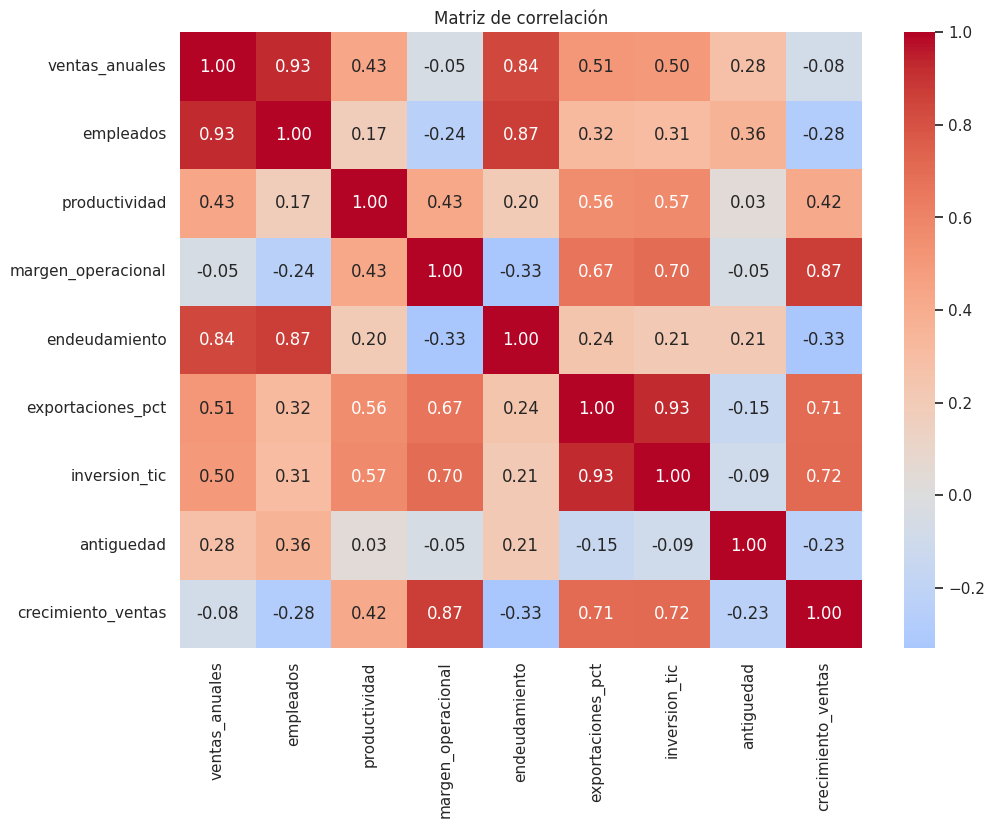

In [11]:
vars_num = ['ventas_anuales', 'empleados', 'productividad', 'margen_operacional', 'endeudamiento',
            'exportaciones_pct', 'inversion_tic', 'antiguedad', 'crecimiento_ventas']
matriz_corr = df[vars_num].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [13]:
analisis_correlaciones = """
1. El par más correlacionado positivamente es exportaciones_pct e inversion_tic (0.93). Tiene sentido económico: las empresas que exportan invierten más en tecnología para cumplir con los estándares y la competencia de los mercados externos.

2. La correlación negativa más fuerte es endeudamiento y crecimiento_ventas (-0.33). Es una relación débil, pero sugiere que las empresas más endeudadas tienden a crecer menos.

3. Sí hay pares que podrían ser redundantes: ventas_anuales y empleados (0.93), y también margen_operacional y crecimiento_ventas (0.87). Si dos variables miden casi lo mismo, el clustering cuenta esa dimensión dos veces y le da más peso del que merece en la distancia.
"""


---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [14]:
X = df.drop(columns=['empresa', 'sector', 'region'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:3])

[[-0.32215502 -0.01904015 -0.52760887 -0.08718771 -1.25608597 -0.58136218
  -0.33141033  1.59034862 -0.24214989]
 [-1.05399303 -1.01740016 -0.63255767 -0.32156328 -0.45632652 -0.72887165
  -0.56736155 -0.71945299 -0.66388602]
 [-0.32417792 -0.26863015 -0.00437858 -0.04582732 -0.07383287 -0.44477932
  -0.60106886  0.78693936  0.0420636 ]]


**3.2 ¿Y si no estandarizamos?** Vamos a comprobar con datos por qué el paso anterior no es opcional.

1. Guarda en `varianzas_sin_escalar` la **varianza de cada columna de `X`** (sin estandarizar), ordenada de mayor a menor. Imprímela.
2. Aplica K-Means **directamente sobre `X`, sin estandarizar**, con `n_clusters=5`, `init='k-means++'`, `n_init=10` y `random_state=42`. Guarda las etiquetas en `clusters_sin_escalar`.
3. Imprime cuántas empresas quedaron en cada grupo y el promedio de cada variable por grupo.

> El `k=5` de este punto es **provisional**: solo sirve para la comparación. En el Ejercicio 4 van a decidir el k de verdad.

In [15]:
varianzas_sin_escalar = X.var().sort_values(ascending=False)
print(varianzas_sin_escalar)
print("\n% de la varianza total:\n", (varianzas_sin_escalar / varianzas_sin_escalar.sum() * 100).round(2))

km_sin = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
clusters_sin_escalar = km_sin.fit_predict(X)

print("\nEmpresas por grupo:\n", pd.Series(clusters_sin_escalar).value_counts().sort_index())
print("\nPromedio por grupo:")
display(X.groupby(clusters_sin_escalar).mean())

ventas_anuales       30,777,134.12
empleados                 3,158.95
productividad             1,577.51
exportaciones_pct           336.38
endeudamiento               298.94
crecimiento_ventas          119.45
antiguedad                   99.55
margen_operacional           52.82
inversion_tic                 8.84
dtype: float64

% de la varianza total:
 ventas_anuales       99.98
empleados             0.01
productividad         0.01
exportaciones_pct     0.00
endeudamiento         0.00
crecimiento_ventas    0.00
antiguedad            0.00
margen_operacional    0.00
inversion_tic         0.00
dtype: float64

Empresas por grupo:
 0    25
1    79
2    72
3    21
4    53
Name: count, dtype: int64

Promedio por grupo:


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
0,"13,119.70",139.96,101.61,1.92,79.81,16.54,3.54,19.88,-3.28
1,361.92,6.42,67.86,4.61,39.46,0.45,0.63,7.34,2.25
2,"4,490.52",52.60,88.41,9.54,45.13,4.47,1.71,28.46,4.22
3,"17,568.06",177.05,101.01,-2.29,83.81,12.16,2.42,21.24,-10.13
4,"9,654.36",80.30,128.64,17.11,55.12,44.05,7.70,13.57,19.78


**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [43]:
analisis_escala = """
1. ventas_anuales concentra casi toda la varianza: el 99.98% del total.

2. La variable que separa los grupos es ventas_anuales (los 5 grupos quedan ordenados por ventas). El algoritmo ignora las demás.

3. La distancia euclidiana suma diferencias al cuadrado, y las diferencias en ventas son miles de veces más grandes que las de margen o endeudamiento, así que ventas decide todo.
"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

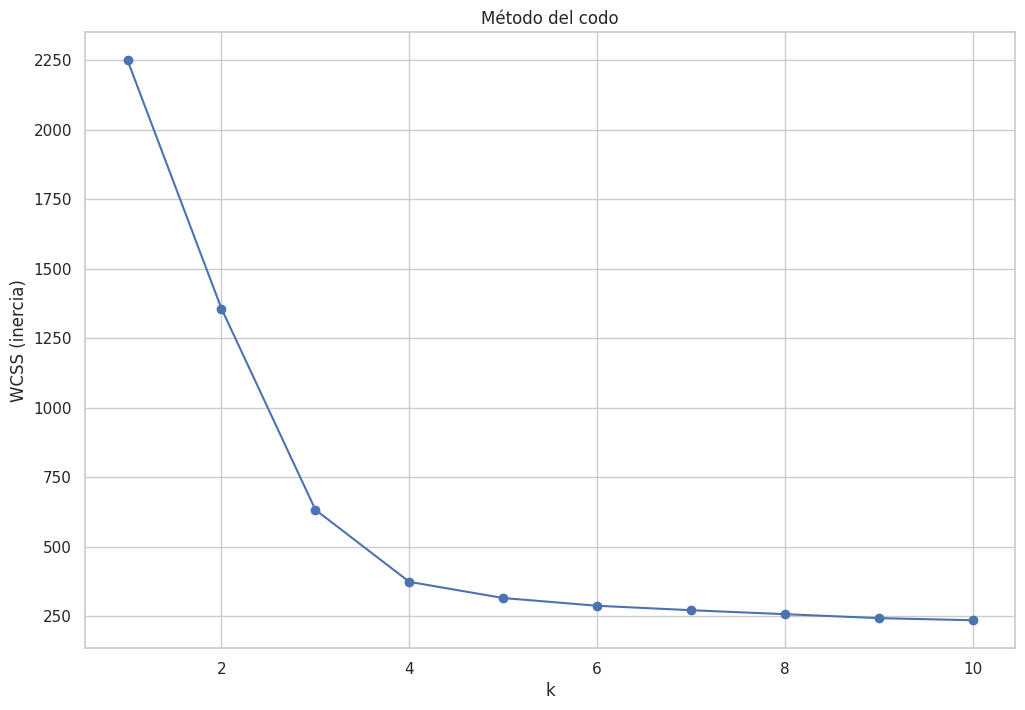

    k     wcss  caida
0   1 2,250.00    NaN
1   2 1,356.60 893.40
2   3   632.70 723.90
3   4   373.40 259.30
4   5   315.20  58.20
5   6   287.40  27.80
6   7   271.40  16.00
7   8   257.10  14.30
8   9   242.90  14.20
9  10   235.30   7.60


In [16]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('k'); plt.ylabel('WCSS (inercia)'); plt.title('Método del codo')
plt.show()

print(pd.DataFrame({'k': range(1, 11), 'wcss': wcss, 'caida': [np.nan] + list(-np.diff(wcss))}).round(1))

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [17]:
analisis_codo = """

El codo está en k = 4: hasta ahí el WCSS cae mucho (de 2,250 a 373), pero al pasar de 4 a 5 la caída es de solo 58 y de ahí en adelante es casi plana.
Los candidatos razonables son k = 3 y k = 4. Se descartan k = 1 y 2, porque todavía hay caídas enormes (893 y 724) y agrupan empresas muy distintas, y k ≥ 5, porque cada grupo extra reduce muy poco el WCSS y solo agrega complejidad.

"""

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

k = 2 -> silueta = 0.453
k = 3 -> silueta = 0.5826
k = 4 -> silueta = 0.5568
k = 5 -> silueta = 0.5555
k = 6 -> silueta = 0.4697
k = 7 -> silueta = 0.3854
k = 8 -> silueta = 0.3031
k = 9 -> silueta = 0.2211
k = 10 -> silueta = 0.2286


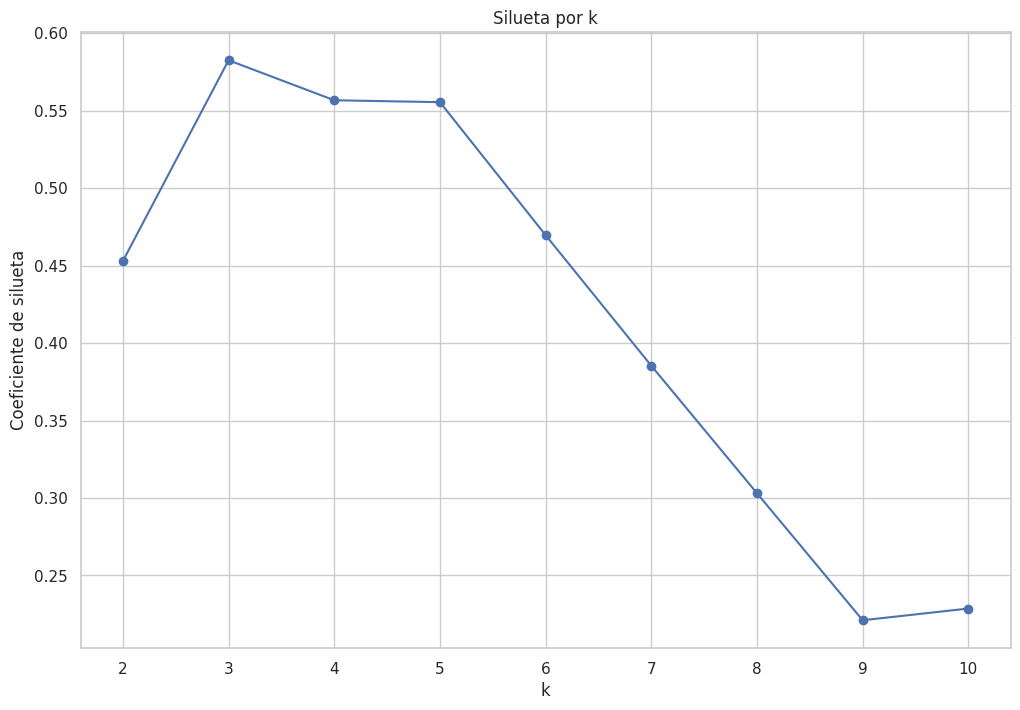

In [18]:
silhouette_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    s = silhouette_score(X_scaled, etiquetas)
    silhouette_scores.append(s)
    print("k =", k, "-> silueta =", round(s, 4))

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('k'); plt.ylabel('Coeficiente de silueta'); plt.title('Silueta por k')
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [19]:
analisis_silueta = """
### TU TEXTO AQUÍ ###
"""

analisis_silueta = """
La silueta es máxima en k = 3 (0.583), y k = 4 (0.557) y k = 5 (0.556) quedan muy cerca. Un valor de 0.58 indica grupos cohesionados y bien separados. Hay una pequeña tensión: la silueta favorece 3 y el codo favorece 4.

"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [20]:
print("k con mayor silueta:", range(2, 11)[int(np.argmax(silhouette_scores))])
k_optimo = 4

print("El equipo trabajará con k =", k_optimo)

k con mayor silueta: 3
El equipo trabajará con k = 4


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [40]:
justificacion_k = """
Elegimos k = 4. El codo lo marca (la caída de WCSS pasa de 259 a 58) y su silueta (0.557) es casi igual a la de k = 3 (0.583). Con k = 3, las pymes maduras y las microempresas quedarían juntas aunque necesitan instrumentos distintos, y cuatro programas son manejables para Bancóldex.

"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [22]:
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
kmeans.fit(X_scaled)
df['cluster_kmeans'] = kmeans.labels_

conteo = df['cluster_kmeans'].value_counts().sort_index()
print(pd.DataFrame({'empresas': conteo, '% del total': (conteo / len(df) * 100).round(1)}))

                empresas  % del total
cluster_kmeans                       
0                     71        28.40
1                     44        17.60
2                     57        22.80
3                     78        31.20


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [23]:
perfil_clusters = df.groupby('cluster_kmeans')[list(X.columns)].mean()
perfil_clusters

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"4,402.50",51.90,87.87,9.29,44.85,3.26,1.58,29.00,3.81
1,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
3,338.11,5.86,68.16,4.54,39.38,0.39,0.61,7.10,2.24


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

Silueta final: 0.5568


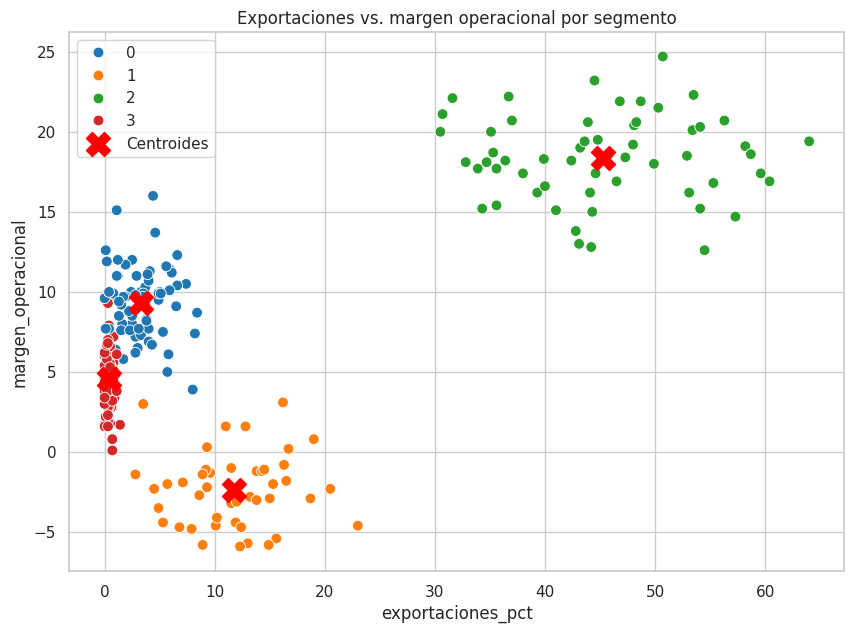

In [24]:
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print("Silueta final:", round(silueta_final, 4))

centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='exportaciones_pct', y='margen_operacional',
                hue='cluster_kmeans', palette='tab10', s=60)
plt.scatter(centroides_originales[:, 5], centroides_originales[:, 3],
            c='red', marker='X', s=300, label='Centroides')
plt.legend(); plt.title('Exportaciones vs. margen operacional por segmento')
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

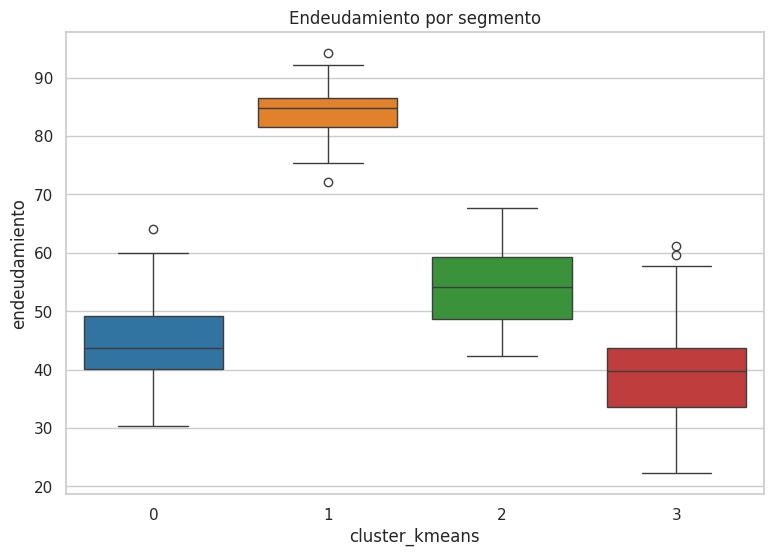

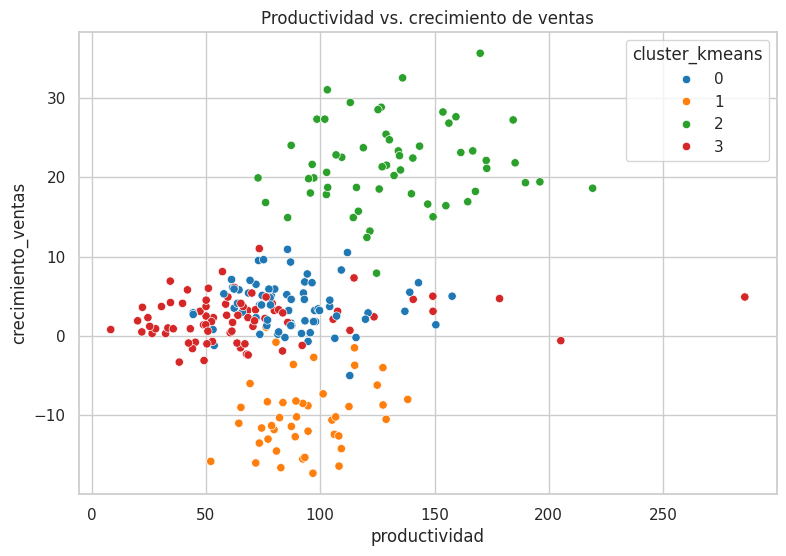

In [25]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='cluster_kmeans', y='endeudamiento', palette='tab10')
plt.title('Endeudamiento por segmento')
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='productividad', y='crecimiento_ventas', hue='cluster_kmeans', palette='tab10')
plt.title('Productividad vs. crecimiento de ventas')
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [26]:
nombres_clusters = [
    "Maduras estables de mercado interno",
    "Grandes sobreendeudadas en declive",
    "Exportadoras dinámicas y tecnificadas",
    "Microempresas jóvenes de baja escala",

]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Maduras estables de mercado interno
Cluster 1: Grandes sobreendeudadas en declive
Cluster 2: Exportadoras dinámicas y tecnificadas
Cluster 3: Microempresas jóvenes de baja escala


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [27]:
descripcion_clusters = """
Cluster 0 (71 empresas, 28.4%): medianas y antiguas (29 años), 52 empleados, margen 9.3%, deuda 45%, casi sin exportar. Oportunidad: modernizarse y tecnificarse.

Cluster 1 (44, 17.6%): las más grandes (166 empleados) pero con margen -2.4%, endeudamiento 84% y ventas cayendo 10%. Problema: sobreendeudamiento y pérdida de rentabilidad.

Cluster 2 (57, 22.8%): las más productivas (132) y rentables (margen 18.4%), exportan 45% y crecen 22%. Oportunidad: escalar su internacionalización.

Cluster 3 (78, 31.2%): microempresas jóvenes (7 años, 6 empleados), baja productividad (68) y casi sin exportar ni invertir en tecnología. Problema: poca escala y baja capacidad productiva.

"""

---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [28]:
!pip install kmodes --quiet

In [29]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [30]:
df_mixto = df[list(X.columns) + ['sector']].copy()
indice_categoricas = [df_mixto.columns.get_loc('sector')]   # da [9]
matriz_mixta = df_mixto.to_numpy()

scaler_mixto = StandardScaler()
matriz_mixta[:, :9] = scaler_mixto.fit_transform(matriz_mixta[:, :9].astype(float))
matriz_mixta[:, 9] = LabelEncoder().fit_transform(matriz_mixta[:, 9])

print(matriz_mixta[:3])

[[-0.32215502244818983 -0.019040151619805316 -0.5276088744673821
  -0.0871877106365195 -1.256085972320208 -0.5813621752210532
  -0.3314103334258739 1.5903486182423119 -0.2421498859617228 1]
 [-1.0539930303588514 -1.0174001616470525 -0.6325576693059609
  -0.3215632768637223 -0.45632651776549416 -0.7288716547061528
  -0.5673615472156539 -0.7194529869340696 -0.6638860193192588 1]
 [-0.3241779217518744 -0.26863015412661706 -0.004378584815428655
  -0.04582731659642492 -0.07383286558715263 -0.4447793238459608
  -0.6010688634713367 0.7869393642679183 0.04206359521400809 1]]


**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [31]:
kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
df['cluster_kproto'] = kproto.fit_predict(matriz_mixta, categorical=indice_categoricas)

**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [32]:
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
display(comparacion)

perfil_kproto = df.groupby('cluster_kproto')[list(X.columns)].mean()
perfil_kproto['sector_moda'] = df.groupby('cluster_kproto')['sector'].agg(lambda s: s.mode().iloc[0])
display(perfil_kproto)

cluster_kproto,0,1,2,3
cluster_kmeans,,,,
0,0,71,0,0
1,0,0,0,44
2,0,0,57,0
3,78,0,0,0


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector_moda
cluster_kproto,,,,,,,,,,
0,338.11,5.86,68.16,4.54,39.38,0.39,0.61,7.10,2.24,Comercio
1,"4,402.50",51.90,87.87,9.29,44.85,3.26,1.58,29.00,3.81,Manufactura
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55,TIC
3,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96,Manufactura


**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [41]:
analisis_kprototypes = """
Los dos algoritmos encontraron exactamente los mismos grupos: en la tabla comparacion cada fila tiene una sola casilla llena. Incluir el sector no cambió nada, porque los grupos ya quedaban definidos por las variables numéricas (ventas, margen, exportaciones, endeudamiento). K-Prototypes valdría la pena si el sector o la región definieran el instrumento a aplicar, por ejemplo líneas de crédito distintas por sector.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [34]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [35]:
nuevas_scaled = scaler.transform(nuevas_empresas[X.columns])
clusters_nuevas = kmeans.predict(nuevas_scaled)

for sol, c in zip(nuevas_empresas.index, clusters_nuevas):
    print("%s -> cluster %d: %s" % (sol, c, nombres_clusters[c]))

Solicitud A -> cluster 2: Exportadoras dinámicas y tecnificadas
Solicitud B -> cluster 3: Microempresas jóvenes de baja escala
Solicitud C -> cluster 1: Grandes sobreendeudadas en declive


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [36]:
recomendaciones = [
    "Cluster 0 (maduras estables): asistencia técnica y crédito de modernización, porque tienen margen de 9.3% pero invierten solo 1.6% en TIC y exportan 3.3%. Indicador: aumento de la inversión en TIC y de la productividad.",
    "Cluster 1 (grandes sobreendeudadas): reestructuración de pasivos, porque su endeudamiento es 84%, su margen es -2.4% y sus ventas caen 10%. Indicador: baja del endeudamiento y margen operacional positivo.",
    "Cluster 2 (exportadoras dinámicas): programa de internacionalización y garantías de crédito para crecer, porque ya exportan 45% y tienen margen de 18.4%. Indicador: aumento de las exportaciones.",
    "Cluster 3 (microempresas jóvenes): microcrédito y capacitación básica en gestión, porque tienen solo 6 empleados, productividad de 68 y exportan 0.4%. Indicador: crecimiento de ventas y productividad.",
    # una recomendación por segmento
]

for r in recomendaciones:
    print("-", r)

- Cluster 0 (maduras estables): asistencia técnica y crédito de modernización, porque tienen margen de 9.3% pero invierten solo 1.6% en TIC y exportan 3.3%. Indicador: aumento de la inversión en TIC y de la productividad.
- Cluster 1 (grandes sobreendeudadas): reestructuración de pasivos, porque su endeudamiento es 84%, su margen es -2.4% y sus ventas caen 10%. Indicador: baja del endeudamiento y margen operacional positivo.
- Cluster 2 (exportadoras dinámicas): programa de internacionalización y garantías de crédito para crecer, porque ya exportan 45% y tienen margen de 18.4%. Indicador: aumento de las exportaciones.
- Cluster 3 (microempresas jóvenes): microcrédito y capacitación básica en gestión, porque tienen solo 6 empleados, productividad de 68 y exportan 0.4%. Indicador: crecimiento de ventas y productividad.


**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [37]:
limitaciones = """
1. K-Means supone grupos esféricos y de tamaño parecido.
2. Las empresas en la frontera entre dos grupos pueden quedar mal clasificadas.
3. Los segmentos dependen de las variables elegidas y del k, no son un hecho de la economía colombiana.
4. Correlación no es causalidad: no se puede concluir que el endeudamiento cause la caída de las ventas.
5. Los segmentos pueden cambiar si se repite el ejercicio el año siguiente.
"""

**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [42]:
validacion_negocio = """
 Pediríamos evidencia adicional: otras variables, datos de otros años y la opinión de los analistas de crédito. Como prueba cuantitativa, verificaríamos con un ANOVA o Kruskal-Wallis que las variables difieren entre grupos. Antes de escalar, haríamos un piloto de cada programa en una muestra de empresas, con un grupo de control.

"""

---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [44]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DEL TALLER DE CLUSTERING  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-clustering-pymes-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        if v == 0:                            # -0.0 y 0.0 son el mismo valor
            v = 0.0
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, _np.ndarray):
        return _canon(x.tolist())
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


_EJERCICIOS = {
    "1": "Ejercicio 1 · Carga y exploración",
    "2": "Ejercicio 2 · Relaciones entre variables",
    "3": "Ejercicio 3 · Preprocesamiento y escala",
    "4": "Ejercicio 4 · Elección de k",
    "5": "Ejercicio 5 · K-Means e interpretación",
    "6": "Ejercicio 6 · K-Prototypes con el sector",
    "7": "Ejercicio 7 · El modelo en producción",
    "A": "Análisis escrito (lo califica la profesora)",
}

#  (punto, título, huellas aceptadas, cómo se obtiene el resultado, pista si falla)
#  Varias huellas en un mismo punto = ese punto depende del k que eligió el grupo,
#  y se acepta cualquier k razonable.
_PRUEBAS = [
    ("1.1", "Base cargada correctamente",
     ("21fef5bc81646de8",),
     lambda: [len(df), sorted(str(c) for c in df.columns if c not in ('cluster_kmeans', 'cluster_kproto')), round(float(df['ventas_anuales'].sum()), 2), round(float(df['productividad'].mean()), 4)],
     "Carga pymes_colombia.csv completo en df, sin cambiar ni renombrar columnas."),
    ("1.2", "Nulos totales y empresas por sector",
     ("82750ec4ed2c94b8",),
     lambda: [int(n_nulos), conteo_sector, round(float(df['endeudamiento'].std()), 4), round(float(df['crecimiento_ventas'].sum()), 2)],
     "n_nulos debe ser UN solo número (el total de toda la base, no una serie por columna) y conteo_sector el número de empresas de cada sector."),
    ("2.1", "Matriz de correlación de las 9 variables numéricas",
     ("285dd981a1169572",),
     lambda: [list(matriz_corr.shape), sorted(str(c) for c in matriz_corr.columns), round(float(matriz_corr.values.sum()), 4), round(float(matriz_corr.loc['exportaciones_pct', 'inversion_tic']), 4)],
     "La matriz debe ser de 9x9: calcúlala sobre df sin las columnas empresa, sector y region."),
    ("3.1", "Variables seleccionadas y estandarizadas",
     ("f92a6704ca04b713",),
     lambda: [list(X.shape), list(str(c) for c in X.columns), _np.round(_np.asarray(X_scaled)[[0, 124, 249]].astype(float), 4).tolist(), round(float(_np.asarray(X_scaled).astype(float).std(axis=0).mean()), 4)],
     "X son las 9 variables numéricas en el mismo orden del CSV, y X_scaled el resultado de scaler.fit_transform(X) con StandardScaler."),
    ("3.2", "Efecto de no estandarizar",
     ("fd58a9cae8024db2",),
     lambda: [varianzas_sin_escalar.round(2), sorted(_pd.Series(clusters_sin_escalar).value_counts().tolist())],
     "varianzas_sin_escalar es X.var() ordenada de mayor a menor, SIN estandarizar. Y el K-Means de este punto va sobre X (no sobre X_scaled), con n_clusters=5 y random_state=42."),
    ("4.1", "Método del codo (lista wcss)",
     ("187dc591a56295c4",),
     lambda: [len(wcss), [round(float(w), 1) for w in wcss[:4]]],
     "wcss debe tener 10 elementos, uno por cada k de 1 a 10, calculados sobre X_scaled con init='k-means++', n_init=10 y random_state=42."),
    ("4.2", "Coeficiente de silueta (lista silhouette_scores)",
     ("919b9299063407be",),
     lambda: [len(silhouette_scores), [round(float(s), 3) for s in silhouette_scores[:3]]],
     "silhouette_scores debe tener 9 elementos, uno por cada k de 2 a 10 (el de k=1 no existe), calculados sobre X_scaled con n_init=10 y random_state=42."),
    ("5.1", "K-Means final entrenado y etiquetas en df",
     ("24f380947694aec1",
      "258e920d08bbb80d",
      "2fb2013e4e3509a5",
      "372fb663109bf318",
      "574c75782e77ad46",
      "6be856106fbdcda5",
      "6bfbf5d142555c44",
      "6d02591e9b9d5e26",
      "6e0acaefac230acb",
      "708333a8476d9391",
      "77a8eca15b3af411",
      "bd93646c2d0857b2",
      "c9c3df5fd40dec82",
      "d7e3a0237cd8f9c5",
      "e1ebb665316f06ec",
      "e353fdfe72ca578d",
      "f0776e5ea1888707",
      "f8a1841da48619c0",
      "fb2ada8f7c034bc1",),
     lambda: [int(kmeans.n_clusters), sorted(df['cluster_kmeans'].value_counts().tolist()), round(float(kmeans.inertia_), 2)],
     "Entrena el KMeans sobre X_scaled (no sobre X) con n_clusters=k_optimo, init='k-means++', n_init=10 y random_state=42, y guarda las etiquetas en la columna cluster_kmeans."),
    ("5.2", "Perfil promedio de cada segmento",
     ("007f3c93c7f18d27",
      "086fdc54cd79ad3d",
      "09e4dd4038c94295",
      "154968e4e20c4318",
      "2347c1fe3638bf15",
      "2ba5fb2303ac9953",
      "36f5183f48d160ff",
      "3fc03de0f4d3e596",
      "5b276874eb928612",
      "5bb823c96e30905b",
      "658160ce6688e786",
      "70cd7218b47402f3",
      "710467cade4edfd1",
      "71c4a9e81b4814a2",
      "789cfad86e29abec",
      "9fb865f5a6c33245",
      "c1e12b3851aa2e6b",
      "d2ae8c4c8225cfa9",
      "f31afdb6867c34cd",),
     lambda: perfil_clusters[list(X.columns)].sort_values('ventas_anuales').round(2).reset_index(drop=True),
     "perfil_clusters es el promedio de las 9 variables numéricas por cluster: agrupa df por cluster_kmeans y saca la media (sin incluir la columna del cluster como variable)."),
    ("5.3", "Silueta final y centroides en unidades originales",
     ("09168179481bef61",
      "0f1e36ac8868d6dc",
      "1ddad4ae3e7f88fe",
      "1fbd083bce7876dc",
      "2088e4fc5f6a04f4",
      "323d53fe8ea9ef14",
      "5e57994b1d33180e",
      "6e7b610567f528ff",
      "75bd91c26d723274",
      "7ff38cf016a428a1",
      "828eae0a37c0380a",
      "89e0f52d134717f4",
      "8eb8dbd75d929748",
      "a4065bd17f293581",
      "af04f027742ddf20",
      "c66c1549743c8f86",
      "cce04f8707bbf862",
      "e65f6674e360f686",
      "f6f8a38aa037f177",),
     lambda: [round(float(silueta_final), 4), sorted(_np.round(_np.asarray(centroides_originales).astype(float).sum(axis=1), 2).tolist())],
     "silueta_final se calcula con silhouette_score(X_scaled, df['cluster_kmeans']), y centroides_originales con scaler.inverse_transform(kmeans.cluster_centers_)."),
    ("6.1", "Matriz mixta lista para K-Prototypes",
     ("0b410a9134798752",),
     lambda: [list(matriz_mixta.shape), list(indice_categoricas), _np.round(_np.asarray(matriz_mixta)[[0, 249], 0:9].astype(float), 4).tolist(), sorted(set(int(v) for v in _np.asarray(matriz_mixta)[:, 9]))],
     "matriz_mixta debe tener 10 columnas: las 9 numéricas estandarizadas (posiciones 0 a 8) y sector codificado con LabelEncoder en la posición 9. Ojo: se estandarizan SOLO las columnas 0 a 8."),
    ("7.1", "Clasificación de las tres solicitudes nuevas",
     ("03302f50031433ff",
      "1e13fdecc4336ff4",
      "1f79a01084c7c6f0",
      "290632fbf05d045d",
      "30a98799190e1832",
      "310552a89751795f",
      "35f952ef56b9cf62",
      "4a0fde5682b487a6",
      "717b25e9dd59eb3a",
      "725cd858e4df65de",
      "904a2b388895a5c1",
      "a06c07f13bc53402",
      "ad5e099e9a4c1de0",
      "b676daa74a43c5bb",
      "bcf4af1b6870a60a",
      "efba0673f79857e2",
      "f5e15685c5b55293",),
     lambda: [[round(float(perfil_clusters.loc[c, 'ventas_anuales']), 2) for c in clusters_nuevas], _np.round(_np.asarray(nuevas_scaled).astype(float), 3).tolist()],
     "Usa scaler.transform(nuevas_empresas) —NO fit_transform— y luego kmeans.predict(). Este punto también depende de que perfil_clusters (punto 5.2) esté bien."),
]

#  Puntos de análisis escrito: valen 8 puntos y los califica la profesora.
#  Aquí solo se comprueba que el grupo haya escrito algo.
_REVISION = [
    ("A1", "Análisis de las estadísticas descriptivas", lambda: analisis_descriptivo, "texto", 350),
    ("A2", "Lectura económica de las correlaciones", lambda: analisis_correlaciones, "texto", 300),
    ("A3", "El efecto de la escala", lambda: analisis_escala, "texto", 300),
    ("A4", "Lectura del método del codo", lambda: analisis_codo, "texto", 200),
    ("A5", "Lectura del coeficiente de silueta", lambda: analisis_silueta, "texto", 200),
    ("A6", "Justificación del k elegido", lambda: justificacion_k, "texto", 250),
    ("A7", "Nombres de los segmentos", lambda: nombres_clusters, "nombres", 3),
    ("A8", "Descripción de cada segmento", lambda: descripcion_clusters, "texto", 600),
    ("A9", "Aporte de K-Prototypes y del sector", lambda: analisis_kprototypes, "texto", 350),
    ("A10", "Recomendaciones de política", lambda: recomendaciones, "lista", 3),
    ("A11", "Limitaciones del análisis", lambda: limitaciones, "texto", 400),
    ("A12", "Validación de los segmentos con el cliente", lambda: validacion_negocio, "texto", 300),
]


def _estado_de(prueba):
    clave, _titulo, esperadas, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) in esperadas else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"

    largo_minimo = 8 if tipo == "nombres" else 60
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= largo_minimo and "###" not in t]
    if not utiles:
        return "falta", "sigue con la lista de ejemplo"
    if len(utiles) < minimo:
        return "mal", "van %d de %d (mínimo %d caracteres cada uno)" % (
            len(utiles), minimo, largo_minimo)
    return "ok", "%d elementos" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_taller():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 68)
    print("  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING")
    print("=" * 68)

    ejercicio_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        ejercicio = clave.split(".")[0]
        if ejercicio != ejercicio_actual:
            ejercicio_actual = ejercicio
            print("\n  " + _EJERCICIOS[ejercicio])
        print("    %s  %-5s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    llenas = round(20 * correctos / total)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 68)
    print("  CÓDIGO: %d de %d puntos automáticos" % (correctos, total))
    print("  [%s]" % barra)
    print("-" * 68)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Los 12 puntos de código están completos!")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla.")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los ejercicios son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 68)
    print("  📝 ANÁLISIS ESCRITO · 8 puntos que califica la profesora")
    print("     Aquí solo se comprueba que hayan escrito algo; el contenido lo")
    print("     evalúa la profesora. Escribir mucho no da puntos por sí solo.\n")
    escritos = 0
    for item in _REVISION:
        estado, detalle = _estado_revision(item)
        escritos += (estado == "ok")
        print("    %s  %-5s %-45s %s" % (_ICONO[estado], item[0], item[1], detalle))

    print("\n  Preguntas abiertas respondidas: %d de %d" % (escritos, len(_REVISION)))
    print("=" * 68)
    print("  NOTA AUTOMÁTICA (solo código): %.1f de 12 puntos" % (12.0 * correctos / total))
    print("  + hasta 8 puntos de análisis escrito que asigna la profesora.")
    print("=" * 68)


verificar_taller()


  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING

  Ejercicio 1 · Carga y exploración
    ✅  1.1   Base cargada correctamente
    ✅  1.2   Nulos totales y empresas por sector

  Ejercicio 2 · Relaciones entre variables
    ✅  2.1   Matriz de correlación de las 9 variables numéricas

  Ejercicio 3 · Preprocesamiento y escala
    ✅  3.1   Variables seleccionadas y estandarizadas
    ✅  3.2   Efecto de no estandarizar

  Ejercicio 4 · Elección de k
    ✅  4.1   Método del codo (lista wcss)
    ✅  4.2   Coeficiente de silueta (lista silhouette_scores)

  Ejercicio 5 · K-Means e interpretación
    ✅  5.1   K-Means final entrenado y etiquetas en df
    ✅  5.2   Perfil promedio de cada segmento
    ✅  5.3   Silueta final y centroides en unidades originales

  Ejercicio 6 · K-Prototypes con el sector
    ✅  6.1   Matriz mixta lista para K-Prototypes

  Ejercicio 7 · El modelo en producción
    ✅  7.1   Clasificación de las tres solicitudes nuevas

----------------------------------------------